<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [234]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [235]:
import random

In [236]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [237]:
len(l)

10000

In [238]:
l[:5]

[9, 9, 5, 6, 4]

In [239]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0253
3     0.0577
4     0.0849
5     0.1114
6     0.1342
7     0.1704
8     0.1424
9     0.1073
10    0.0829
11    0.0560
12    0.0275
Name: count, dtype: float64


<Axes: >

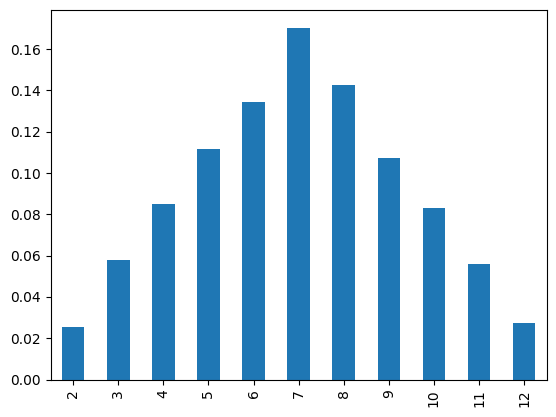

In [240]:
s.plot(kind='bar')

<Axes: >

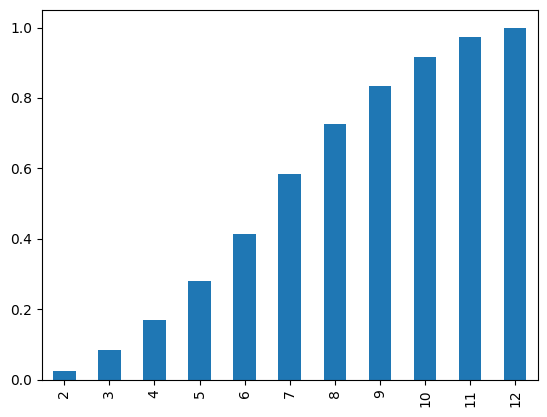

In [241]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [242]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[48.90910506 47.36906603 54.97381187 47.70142511 56.28295448 52.41933259
 46.39870237 59.73173776 55.55136417 40.70995525 44.67657578 37.57605806
 41.54646647 68.88356252 55.17126193 49.83500907 48.27826996 47.93693293
 48.16877994 46.59360292 47.76842049 57.15629408 53.40544373 50.82085919
 56.1978553  55.58728919 52.64801997 49.07291486 44.48115463 55.77462985
 48.85076427 51.66980375 42.86816901 48.7592723  61.20771091 55.81104513
 56.89498022 50.69041859 51.06894347 39.27662943 56.03137956 48.20979549
 65.75869349 49.65068518 52.36518532 58.900957   51.62400626 48.74601505
 42.86616685 48.61749028 49.74462417 58.18924698 56.96980358 38.56373696
 57.73506029 53.89557184 52.29039215 50.24381251 52.69352636 49.89869272
 43.68607926 47.88037394 51.4325509  53.00219036 60.79182029 52.20773714
 48.22763025 54.34085342 41.84030802 42.17627539 56.66820503 61.73327999
 52.27713564 54.02313806 57.5526195  59.22211444 47.15278239 46.40174268
 56.36336678 53.70259584 56.52430351 54.03360905 47

In [243]:
sample.mean()

np.float64(50.0661608684688)

(array([ 16.,  46., 144., 250., 264., 174.,  68.,  31.,   4.,   3.]),
 array([36.50792851, 39.74549191, 42.98305531, 46.22061872, 49.45818212,
        52.69574552, 55.93330892, 59.17087232, 62.40843572, 65.64599912,
        68.88356252]),
 <BarContainer object of 10 artists>)

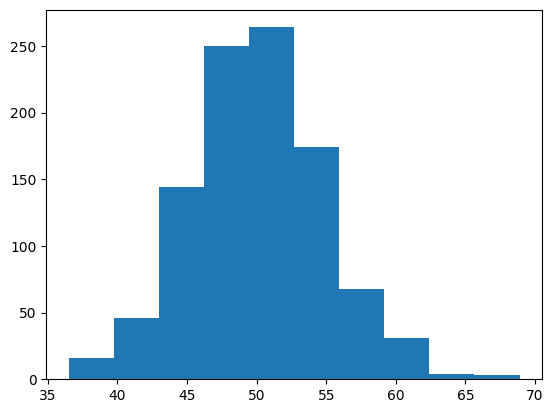

In [244]:
plt.hist(sample,bins=10)

In [245]:
sample_mean=sample.mean()
sample_std=sample.std()

In [246]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [247]:
sample.min()

np.float64(36.50792851330548)

In [248]:
sample.max()

np.float64(68.88356251940485)

In [249]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [250]:
probabilities=[dist.pdf(value) for value in values]

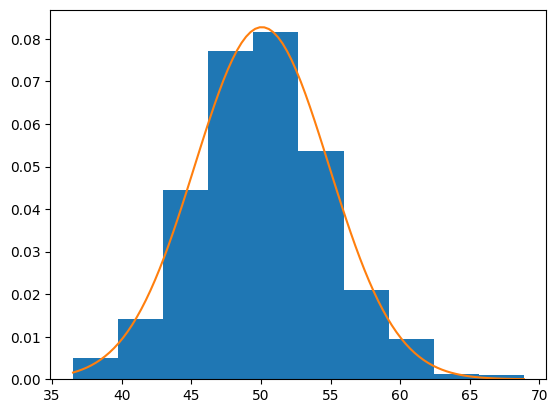

In [251]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_717/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

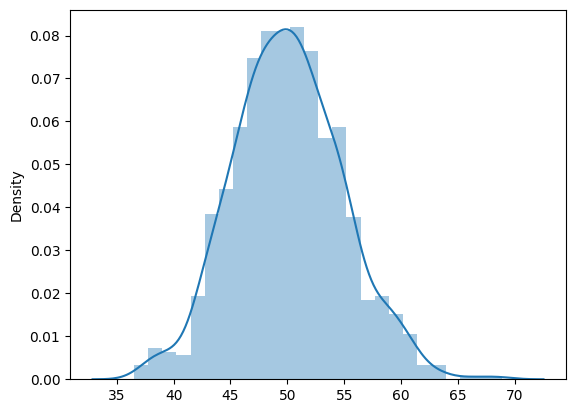

In [252]:
import seaborn as sns
sns.distplot(sample)

KDE

In [253]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [254]:
sample

array([32.99479926, 24.69196887, 11.3101453 , 27.60637469, 11.40246969,
       24.57014985, 26.16921084, 13.06128577, 16.54899793, 25.23609402,
       22.45010153, 20.13356873, 16.05913912, 16.39823558, 16.9323022 ,
       20.23766638, 25.44419223, 27.11904139, 21.35305832, 16.40102475,
       11.46462318, 19.28787768, 17.31371202, 25.20777477, 20.26861674,
       21.92751276, 17.70569611, 25.76289957, 12.17340848, 14.97601675,
       26.60133815, 17.21050025, 20.42616259, 10.92069714, 25.35308498,
       18.63954923, 14.50504731, 27.5246089 , 20.38541833, 21.52709961,
       19.88105765, 26.32169695, 14.3330279 , 26.95807472, 19.7285745 ,
       20.19395143, 19.42625848, 25.98984184, 25.28543567, 16.51368896,
       13.29041069, 23.31527884, 13.69588196, 16.04293262, 21.34440764,
       14.59408941, 19.24031774, 28.64412986, 34.08919197, 27.30584181,
       14.23519589, 13.15068186, 17.15657696, 17.14794659, 21.16125014,
       23.75142393, 17.21757682, 24.05640537, 17.28967211, 22.52

(array([ 1.,  1.,  0., 10.,  7., 10., 17.,  8., 20., 30.,  8., 24., 22.,
        20., 22., 20., 14., 22., 13., 18., 10., 15., 12., 18., 23., 20.,
        25., 41., 46., 39., 46., 55., 50., 53., 56., 45., 48., 29., 31.,
         9., 17.,  9.,  8.,  2.,  2.,  2.,  1.,  0.,  0.,  1.]),
 array([ 7.48115386,  8.48860876,  9.49606366, 10.50351856, 11.51097346,
        12.51842836, 13.52588326, 14.53333816, 15.54079307, 16.54824797,
        17.55570287, 18.56315777, 19.57061267, 20.57806757, 21.58552247,
        22.59297737, 23.60043228, 24.60788718, 25.61534208, 26.62279698,
        27.63025188, 28.63770678, 29.64516168, 30.65261658, 31.66007149,
        32.66752639, 33.67498129, 34.68243619, 35.68989109, 36.69734599,
        37.70480089, 38.71225579, 39.7197107 , 40.7271656 , 41.7346205 ,
        42.7420754 , 43.7495303 , 44.7569852 , 45.7644401 , 46.771895  ,
        47.77934991, 48.78680481, 49.79425971, 50.80171461, 51.80916951,
        52.81662441, 53.82407931, 54.83153421, 55.83898912,

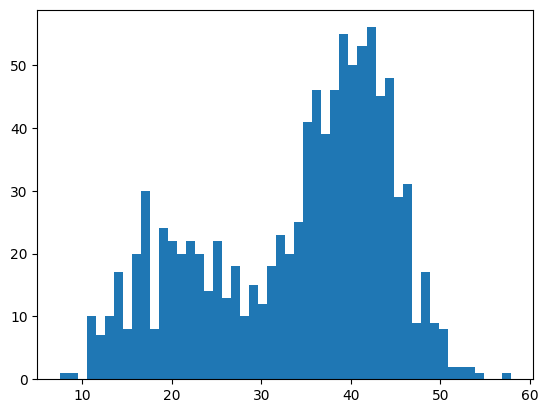

In [255]:
plt.hist(sample,bins=50)

In [256]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [257]:
dataset=sns.load_dataset("iris")

In [258]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

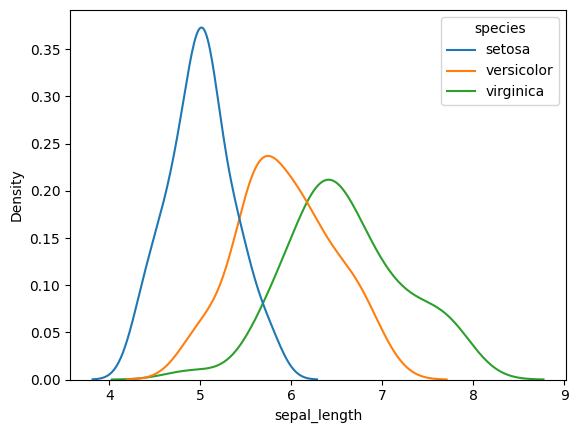

In [259]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

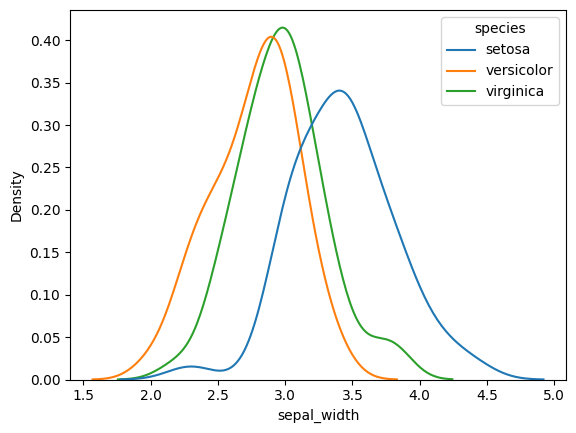

In [260]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

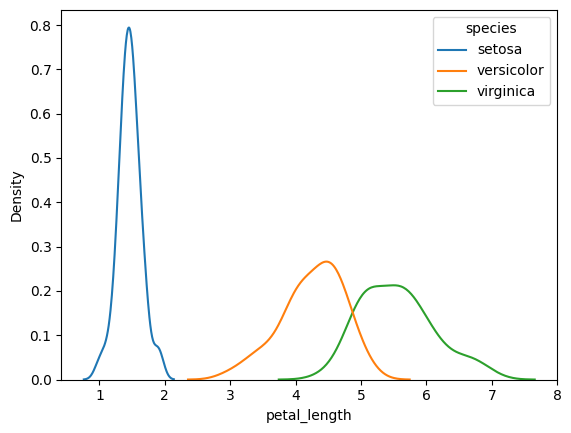

In [261]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

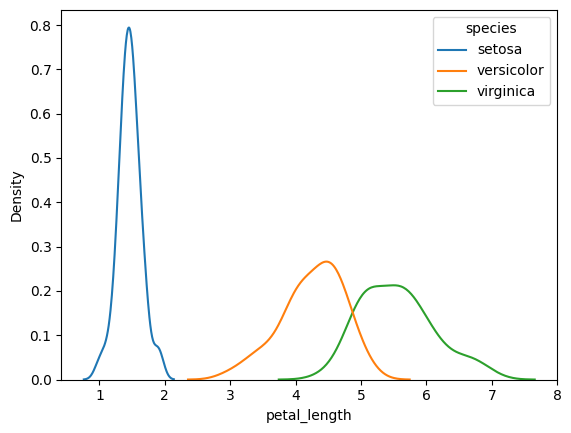

In [262]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [263]:
tips=sns.load_dataset("tips")

In [264]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

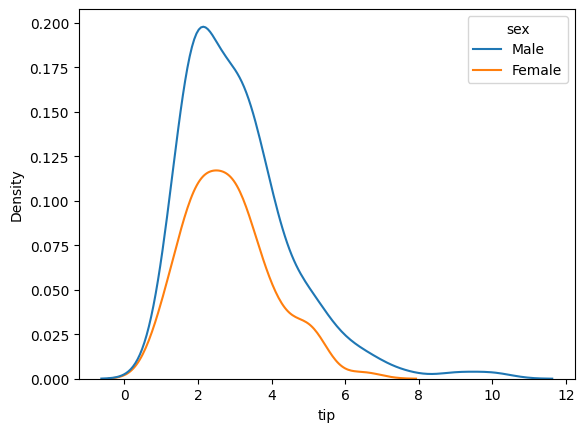

In [265]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

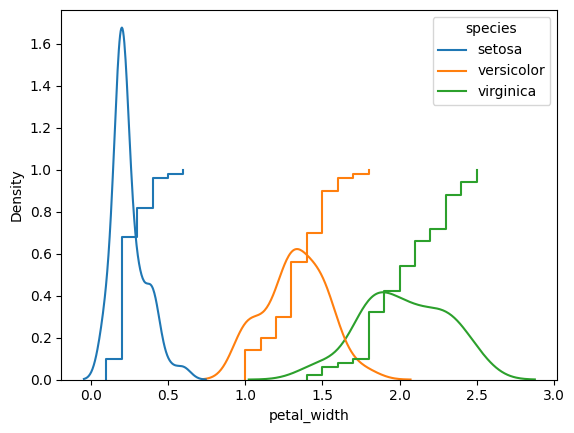

In [266]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [267]:
#contour plots

How to find distribution is normal or not?

In [268]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

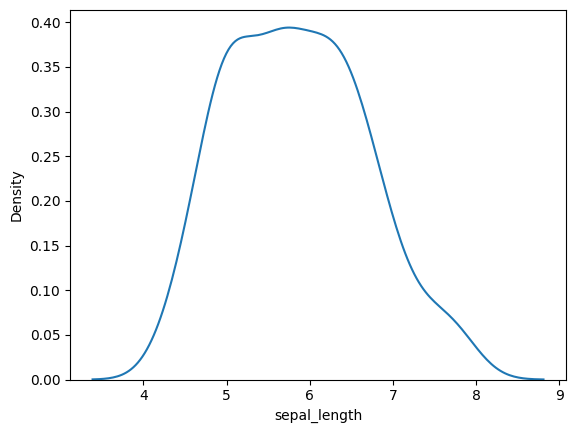

In [269]:
sns.kdeplot(iris["sepal_length"])

In [270]:
temp=sorted(iris['sepal_length'].tolist())

In [271]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [272]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [273]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

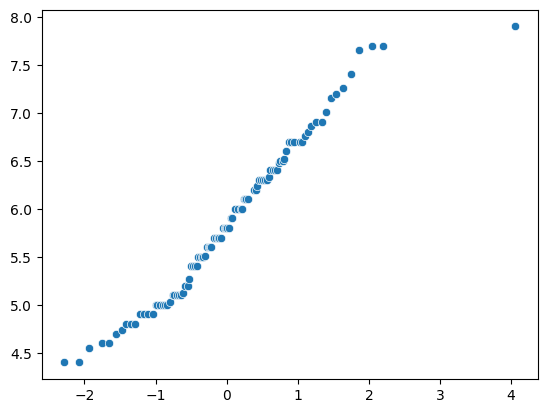

In [274]:
sns.scatterplot(x=x_quant,y=y_quant)

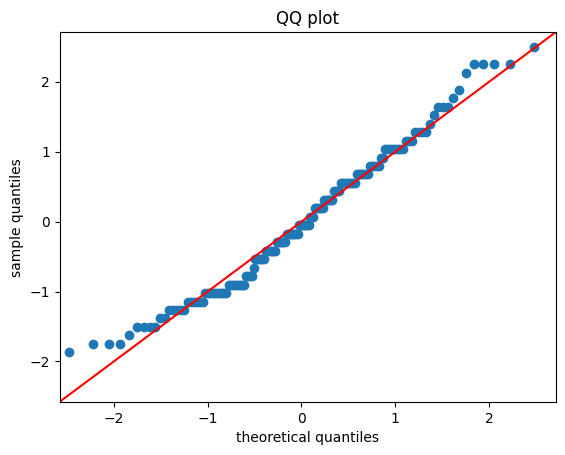

In [275]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [276]:
import scipy.stats as stats

In [277]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([ 97., 105., 100.,  98.,  97.,  89.,  96.,  98., 116., 104.]),
 array([4.20353604e-04, 1.00241939e-01, 2.00063525e-01, 2.99885111e-01,
        3.99706697e-01, 4.99528282e-01, 5.99349868e-01, 6.99171454e-01,
        7.98993040e-01, 8.98814625e-01, 9.98636211e-01]),
 <BarContainer object of 10 artists>)

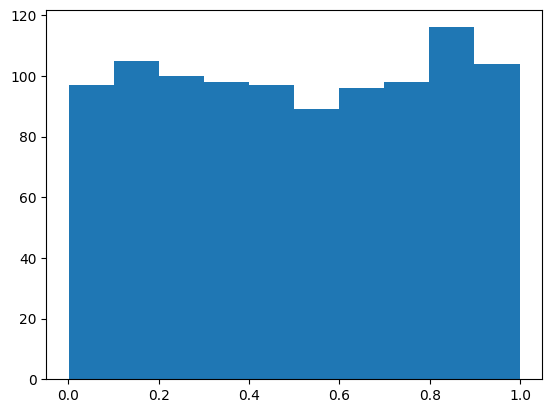

In [278]:
plt.hist(x)

PARETO DISTRIBUTION

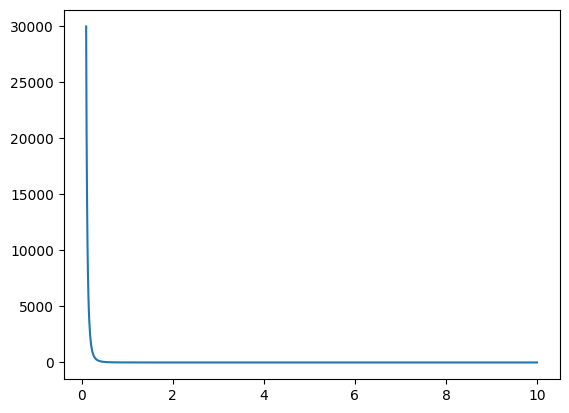

In [279]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

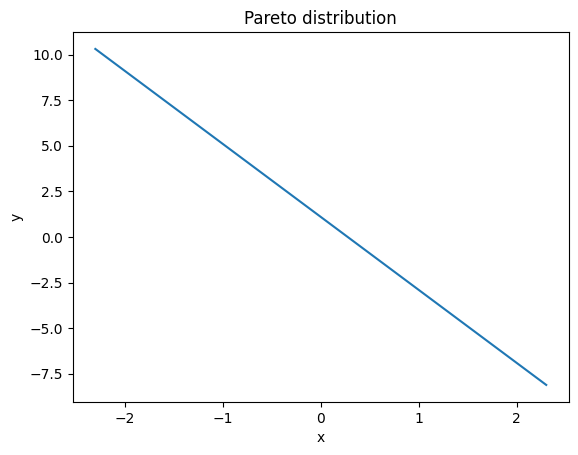

In [280]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [281]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([909.,  53.,  21.,   6.,   5.,   3.,   0.,   2.,   0.,   1.]),
 array([ 1.0000747 ,  3.21621201,  5.43234932,  7.64848663,  9.86462394,
        12.08076125, 14.29689856, 16.51303587, 18.72917318, 20.94531049,
        23.1614478 ]),
 <BarContainer object of 10 artists>)

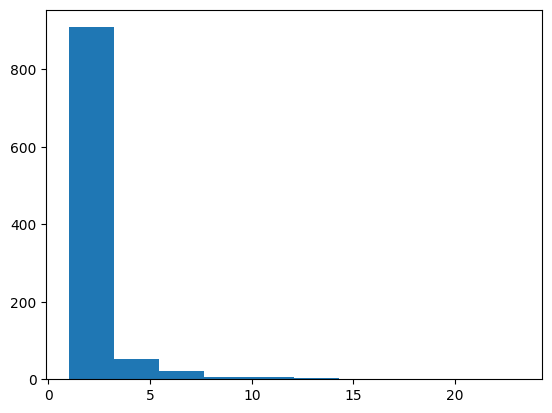

In [282]:
plt.hist(x)

In [283]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

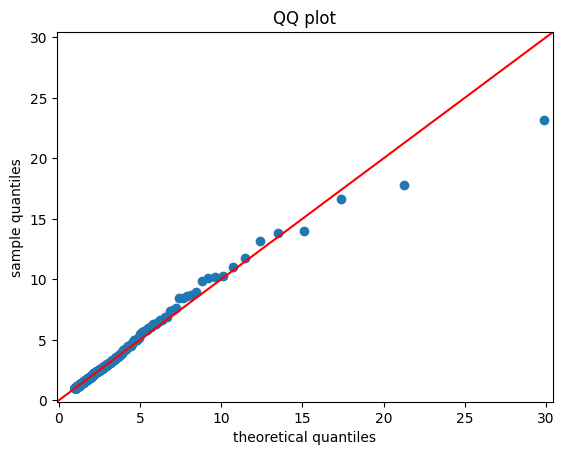

In [284]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [285]:
df=pd.read_csv('/content/battery_health_dataset.csv',usecols=['Battery Age','Cycle Count','Daily Usage Hours'])

df.head()

,Battery Age,Daily Usage Hours,Cycle Count
0,5,9.797617,1267
1,9,7.101557,1500
2,9,10.085255,1500
3,5,7.946047,1153
4,7,9.628460,1500


In [286]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Cycle Count,0.952206


In [287]:
from scipy.stats import stats
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [288]:
df.isnull().sum()
# if missing values use df['column'].fillna(df['column'].mean(),inplace=True)

,0
Battery Age,0
Daily Usage Hours,0
Cycle Count,0


In [289]:
x=df.iloc[:,1:4]
y=df.iloc[:,0]

In [290]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)
'''What does train_test_split() do?
train_test_split() is a function from sklearn.model_selection that divides your dataset into two parts:
- Training data: Used to train the machine-learning model.
- Testing data: Used to check how well the model performs on data it hasn't trained on.

random_state=42 is optional. It makes the random split reproducible, so you get the same split when you run the code again with the same data.'''

"What does train_test_split() do?\ntrain_test_split() is a function from sklearn.model_selection that divides your dataset into two parts:\n- Training data: Used to train the machine-learning model.\n- Testing data: Used to check how well the model performs on data it hasn't trained on.\n\nrandom_state=42 is optional. It makes the random split reproducible, so you get the same split when you run the code again with the same data."

/tmp/ipykernel_717/1170598051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Daily Usage Hours'])


Text(0.5, 1.0, 'Daily Usage Hours QQ plot')

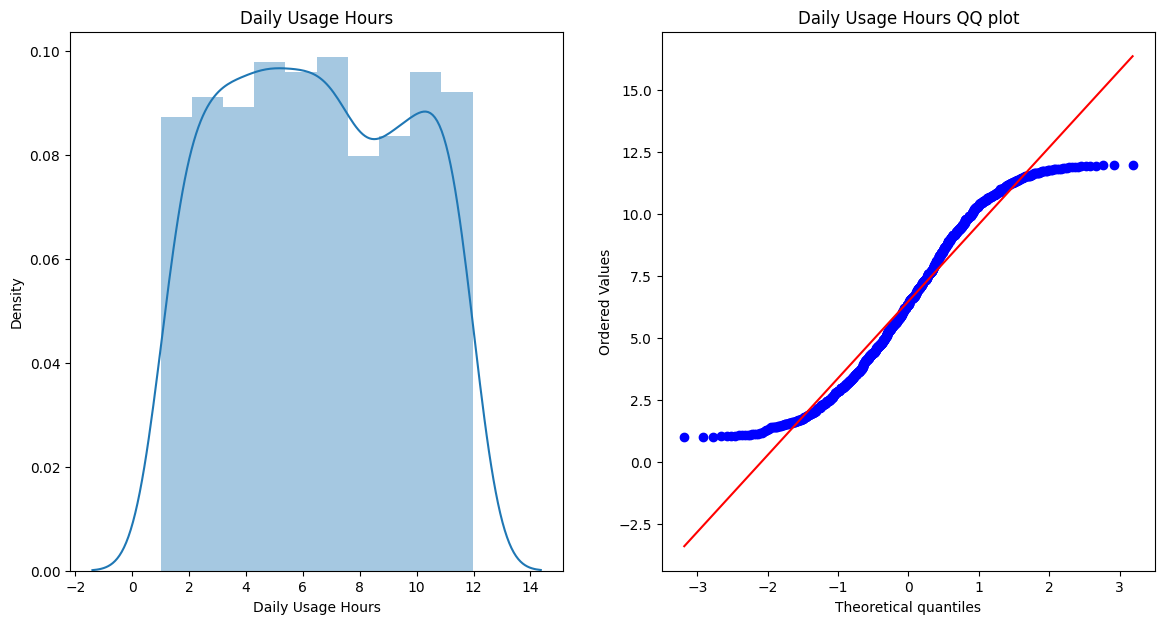

In [291]:
import scipy.stats as stats

plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Daily Usage Hours'])
plt.title("Daily Usage Hours")
plt.subplot(122)
stats.probplot(x_train['Daily Usage Hours'],dist="norm",plot=plt)
plt.title("Daily Usage Hours QQ plot")

/tmp/ipykernel_717/882698.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Cycle Count'])


Text(0.5, 1.0, 'Cycle Count QQ plot')

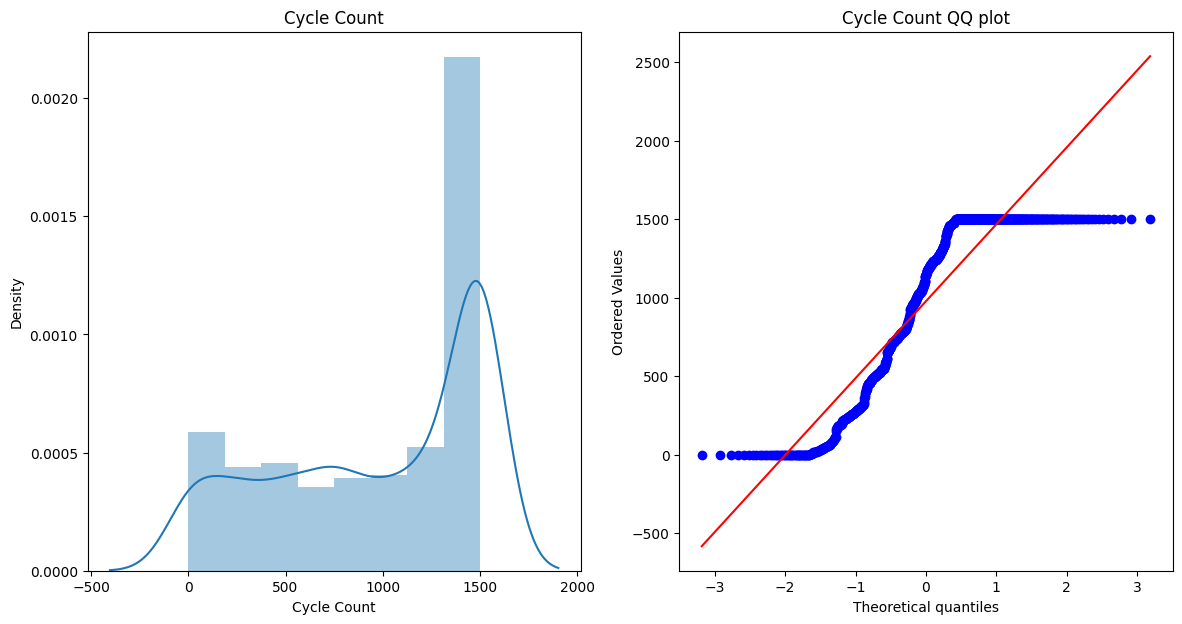

In [292]:
plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Cycle Count'])
plt.title("Cycle Count")
plt.subplot(122)
stats.probplot(x_train['Cycle Count'],dist="norm",plot=plt)
plt.title("Cycle Count QQ plot")


In [293]:
clf1=LogisticRegression()
clf2=DecisionTreeClassifier()

In [294]:
print(y.value_counts())
print(x.shape, y.shape)

Battery Age
5    145
3    134
9    130
7    126
6    123
0    113
2    112
1    109
4    107
8    101
Name: count, dtype: int64
(1200, 2) (1200,)


In [295]:
print(x.head())
print(y.head())
print(x.nunique())

   Daily Usage Hours  Cycle Count
0           9.797617         1267
1           7.101557         1500
2          10.085255         1500
3           7.946047         1153
4           9.628460         1500
0    5
1    9
2    9
3    5
4    7
Name: Battery Age, dtype: int64
Daily Usage Hours    1200
Cycle Count           562
dtype: int64


In [296]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Cycle Count,0.952206


In [297]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred=clf1.predict(x_test)
y_pred2=clf2.predict(x_test)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.2791666666666667
Accuracy DT 0.7208333333333333


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [298]:
trf=FunctionTransformer(np.log1p)

In [301]:
x_train_transform=trf.fit_transform(x_train)
x_test_transform=trf.transform(x_test)

print(x_train_transform)
print(x_test_transform)

     Daily Usage Hours  Cycle Count
740           2.347197     6.152733
659           1.088386     7.313887
695           2.141111     7.138073
232           2.544917     7.313887
938           1.954999     7.085064
..                 ...          ...
270           2.388496     6.886532
383           1.347023     0.000000
614           2.079773     6.270988
52            1.352933     5.509388
330           0.923927     0.000000

[960 rows x 2 columns]
     Daily Usage Hours  Cycle Count
188           2.092663     6.889591
565           2.091114     0.000000
967           2.532318     6.727432
607           2.241913     5.521461
76            2.150943     7.121252
..                 ...          ...
700           1.999809     7.313887
360           2.364217     7.313887
447           1.662818     7.313887
311           2.084181     6.135565
261           1.389027     0.000000

[240 rows x 2 columns]


In [302]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred=clf.predict(x_test_transform)
y_pred2=clf2.predict(x_test_transform)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.5291666666666667
Accuracy DT 0.7125


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
